# 05 – Extended evaluation for the final report
**QM640 Data Analytics Capstone – Binesh Balakrishnan**

This notebook extends notebooks 03 and 04 with the analyses planned in the interim report:
1. Training versus test performance of each RQ4 model (overfitting check).
2. Forward-chaining (expanding-window) cross-validation inside the training period.
3. Calibration of the best model and recalibration on the latest training weeks.
4. A capacity-based operating threshold (flag the top *k*% of tickets by risk) and its confusion matrix.
5. RQ2 robustness: banded reassignment with a reassignment × priority interaction.
6. RQ3 robustness: knowledge-base effect estimated separately before and after the March 2016 process change.

Hyperparameters are fixed at the values chosen by cross-validation in notebook 04 (`results/rq4.json`), so no grid search is repeated.
Output: `results/final_eval.json` and figures in `figures/`.

In [1]:
import os, subprocess
repo = '/content/QM640_data_analytics_capstone'
if os.path.exists('/content') and not os.path.exists(repo):   # Colab: clone the repository
    subprocess.run(['git', 'clone', '-q',
                    'https://github.com/binesh29/QM640_data_analytics_capstone.git', repo], check=True)
if os.path.exists(repo):
    os.chdir(os.path.join(repo, 'notebooks'))
os.makedirs('../figures', exist_ok=True); os.makedirs('../results', exist_ok=True)
print(os.getcwd())

/home/claude/work/repo/notebooks


In [2]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score, f1_score,
                             accuracy_score, brier_score_loss, confusion_matrix)
from sklearn.calibration import calibration_curve
from sklearn.base import clone
from xgboost import XGBClassifier
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import StratifiedTable
from scipy.stats import chi2 as chi2_dist
sys.path.insert(0, '../src'); import plot_style as ps; ps.apply()
warnings.filterwarnings('ignore')
SEED = 42; FIG = Path('../figures'); R = {}
P4 = json.load(open('../results/rq4.json'))['cv']

## 1. Same features and temporal split as notebook 04

In [3]:
inc = pd.read_csv('../data/processed/incidents.csv', parse_dates=['opened_at']).sort_values('opened_at').reset_index(drop=True)
CAT = ['log_priority', 'log_impact', 'log_urgency', 'log_category', 'log_subcategory', 'log_u_symptom',
       'log_contact_type', 'log_location', 'log_assignment_group', 'log_notify']
for c in CAT: inc[c] = inc[c].fillna('Missing').astype(str)
inc['log_u_priority_confirmation'] = inc['log_u_priority_confirmation'].astype(int)
inc['cmdb_ci_missing'] = inc['log_cmdb_ci'].isna().astype(int)
inc['hour_sin'] = np.sin(2 * np.pi * inc['log_hour'] / 24); inc['hour_cos'] = np.cos(2 * np.pi * inc['log_hour'] / 24)
inc['weekend'] = (inc['log_dayofweek'] >= 5).astype(int)
inc['dow'] = inc['log_dayofweek'].astype(str)
cut = int(len(inc) * 0.70)
tr, te = inc.iloc[:cut].copy(), inc.iloc[cut:].copy()
freq = tr['log_caller_id'].value_counts()
for d in (tr, te): d['caller_freq'] = np.log1p(d['log_caller_id'].map(freq).fillna(0))
y_tr, y_te = tr['sla_breach'].values, te['sla_breach'].values
CAT_ALL = CAT + ['dow']
NUM = ['caller_freq', 'hour_sin', 'hour_cos', 'weekend', 'log_u_priority_confirmation', 'cmdb_ci_missing']
FEATS = CAT_ALL + NUM
def prep(scale):
    return ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=30, sparse_output=True), CAT_ALL),
        ('num', StandardScaler() if scale else 'passthrough', NUM)])
pw = (1 - y_tr.mean()) / y_tr.mean()
bp = {k: v['best_params'] for k, v in P4.items()}
models = {
  'Baseline: priority-only LR': Pipeline([('p', ColumnTransformer([('c', OneHotEncoder(handle_unknown='ignore'), ['log_priority'])])),
                                          ('m', LogisticRegression(class_weight='balanced', max_iter=1000))]),
  'Regularised LR': Pipeline([('p', prep(True)), ('m', LogisticRegression(class_weight='balanced', max_iter=3000, solver='liblinear',
                                                                          C=bp['Regularised LR']['C'], penalty=bp['Regularised LR']['penalty']))]),
  'Random forest': Pipeline([('p', prep(False)), ('m', RandomForestClassifier(n_estimators=400, class_weight='balanced_subsample', n_jobs=-1,
                             random_state=SEED, min_samples_leaf=bp['Random forest']['min_samples_leaf'],
                             max_features=bp['Random forest']['max_features']))]),
  'XGBoost': Pipeline([('p', prep(False)), ('m', XGBClassifier(n_estimators=400, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=pw,
                       eval_metric='logloss', random_state=SEED, n_jobs=4, tree_method='hist',
                       max_depth=bp['XGBoost']['max_depth'], learning_rate=bp['XGBoost']['learning_rate']))]),
}
print({k: v for k, v in bp.items()})

{'Baseline: priority-only LR': {}, 'Regularised LR': {'C': 1.0, 'penalty': 'l1'}, 'Random forest': {'max_features': 'sqrt', 'min_samples_leaf': 2}, 'XGBoost': {'learning_rate': 0.1, 'max_depth': 7}}


## 2. Training versus test performance (threshold 0.5)

In [4]:
def metrics(y, s):
    yh = (s >= 0.5).astype(int)
    return {'auc': round(roc_auc_score(y, s), 3), 'pr_auc': round(average_precision_score(y, s), 3),
            'accuracy': round(accuracy_score(y, yh), 3), 'precision': round(precision_score(y, yh, zero_division=0), 3),
            'recall': round(recall_score(y, yh), 3), 'f1': round(f1_score(y, yh), 3), 'brier': round(brier_score_loss(y, s), 3)}
fitted, s_te, rows = {}, {}, []
for name, pipe in models.items():
    m = clone(pipe).fit(tr[FEATS], y_tr); fitted[name] = m
    s_tr = m.predict_proba(tr[FEATS])[:, 1]; s_te[name] = m.predict_proba(te[FEATS])[:, 1]
    rows.append({'model': name, 'train': metrics(y_tr, s_tr), 'test': metrics(y_te, s_te[name])})
    print(name, rows[-1])
R['train_vs_test'] = rows
from scipy.stats import rankdata, norm
def delong2(y, s1, s2):
    pos, neg = y == 1, y == 0; m, n = pos.sum(), neg.sum()
    def comp(s):
        tx, ty, tz = rankdata(s[pos]), rankdata(s[neg]), rankdata(np.r_[s[pos], s[neg]])
        return (tz[:m].sum() - m * (m + 1) / 2) / (m * n), (tz[:m] - tx) / n, 1 - (tz[m:] - ty) / m
    a1, x1, y1 = comp(s1); a2, x2, y2 = comp(s2)
    S = np.cov(np.vstack([x1, x2])) / m + np.cov(np.vstack([y1, y2])) / n
    z = (a1 - a2) / np.sqrt(S[0, 0] + S[1, 1] - 2 * S[0, 1]); return round(a1 - a2, 3), round(z, 2), float(2 * norm.sf(abs(z)))
R['delong_pairs'] = {f'{a} vs {b}': dict(zip(['diff', 'z', 'p_two_sided'], delong2(y_te, s_te[a], s_te[b])))
                     for a, b in [('Random forest', 'Regularised LR'), ('Random forest', 'XGBoost'), ('Regularised LR', 'XGBoost')]}
print(R['delong_pairs'])

Baseline: priority-only LR {'model': 'Baseline: priority-only LR', 'train': {'auc': 0.533, 'pr_auc': 0.453, 'accuracy': 0.594, 'precision': 0.919, 'recall': 0.045, 'f1': 0.085, 'brier': 0.243}, 'test': {'auc': 0.552, 'pr_auc': 0.289, 'accuracy': 0.781, 'precision': 0.884, 'recall': 0.07, 'f1': 0.13, 'brier': 0.24}}


Regularised LR {'model': 'Regularised LR', 'train': {'auc': 0.783, 'pr_auc': 0.739, 'accuracy': 0.705, 'precision': 0.644, 'recall': 0.679, 'f1': 0.661, 'brier': 0.188}, 'test': {'auc': 0.779, 'pr_auc': 0.533, 'accuracy': 0.722, 'precision': 0.436, 'recall': 0.653, 'f1': 0.523, 'brier': 0.185}}


Random forest {'model': 'Random forest', 'train': {'auc': 0.924, 'pr_auc': 0.909, 'accuracy': 0.846, 'precision': 0.82, 'recall': 0.813, 'f1': 0.817, 'brier': 0.137}, 'test': {'auc': 0.785, 'pr_auc': 0.536, 'accuracy': 0.729, 'precision': 0.445, 'recall': 0.66, 'f1': 0.532, 'brier': 0.181}}


XGBoost {'model': 'XGBoost', 'train': {'auc': 0.922, 'pr_auc': 0.905, 'accuracy': 0.841, 'precision': 0.803, 'recall': 0.825, 'f1': 0.814, 'brier': 0.125}, 'test': {'auc': 0.738, 'pr_auc': 0.481, 'accuracy': 0.696, 'precision': 0.4, 'recall': 0.605, 'f1': 0.481, 'brier': 0.195}}
{'Random forest vs Regularised LR': {'diff': np.float64(0.005), 'z': np.float64(1.66), 'p_two_sided': 0.09713560646656275}, 'Random forest vs XGBoost': {'diff': np.float64(0.047), 'z': np.float64(11.76), 'p_two_sided': 6.551467441760611e-32}, 'Regularised LR vs XGBoost': {'diff': np.float64(0.041), 'z': np.float64(9.38), 'p_two_sided': 6.501515798622382e-21}}


## 3. Forward-chaining cross-validation (5 expanding windows inside the training period)

In [5]:
tss = TimeSeriesSplit(n_splits=5)
fc = {n: [] for n in models}; folds = []
for k, (a, b) in enumerate(tss.split(tr)):
    A, B = tr.iloc[a].copy(), tr.iloc[b].copy()
    f = A['log_caller_id'].value_counts()
    for d in (A, B): d['caller_freq'] = np.log1p(d['log_caller_id'].map(f).fillna(0))
    folds.append({'fold': k + 1, 'n_fit': len(A), 'n_val': len(B), 'val_start': str(B['opened_at'].min().date()),
                  'val_end': str(B['opened_at'].max().date()), 'val_breach': round(B['sla_breach'].mean(), 3)})
    for n, pipe in models.items():
        mm = clone(pipe)
        if n == 'XGBoost': mm.set_params(m__scale_pos_weight=(1 - A['sla_breach'].mean()) / A['sla_breach'].mean())
        mm.fit(A[FEATS], A['sla_breach'])
        fc[n].append(round(roc_auc_score(B['sla_breach'], mm.predict_proba(B[FEATS])[:, 1]), 3))
R['forward_chaining'] = {'folds': folds, 'auc': fc, 'mean': {n: round(float(np.mean(v)), 3) for n, v in fc.items()},
                         'sd': {n: round(float(np.std(v, ddof=1)), 3) for n, v in fc.items()}}
pd.DataFrame(fc, index=[f"fold {f['fold']} ({f['val_start']} to {f['val_end']})" for f in folds])

,Baseline: priority-only LR,Regularised LR,Random forest,XGBoost
fold 1 (2016-03-09 to 2016-03-19),0.561,0.704,0.705,0.660
fold 2 (2016-03-19 to 2016-03-30),0.527,0.600,0.556,0.545
fold 3 (2016-03-30 to 2016-04-08),0.531,0.751,0.744,0.682
fold 4 (2016-04-08 to 2016-04-20),0.538,0.768,0.772,0.687
fold 5 (2016-04-20 to 2016-05-02),0.582,0.788,0.788,0.759


## 4. Calibration of the best model and recalibration on the latest training weeks
The training breach rate (42.3%) is far above the test rate (23.3%), so raw probabilities are expected to be too high.
Recalibration: refit the random forest on the first 80% of the training period and fit a Platt (logistic) map on the
remaining 20% (the most recent weeks before the cut-off), then apply it to the test set.

{'recal_window': ['2016-04-18', '2016-05-02'], 'recal_breach': np.float64(0.237), 'raw': {'brier': 0.181, 'mean_pred': np.float64(0.419), 'auc': 0.785}, 'recalibrated': {'brier': 0.146, 'mean_pred': np.float64(0.247), 'auc': 0.776}, 'observed_rate': np.float64(0.233), 'brier_no_skill': np.float64(0.179)}


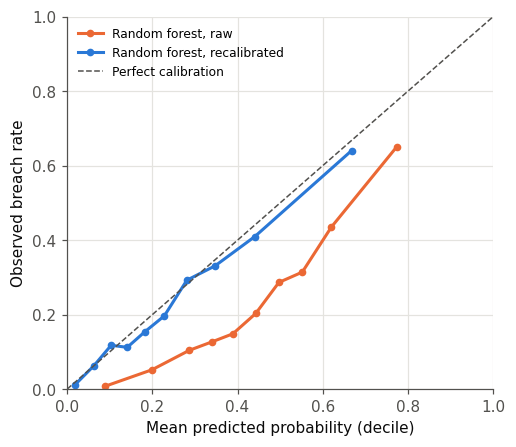

In [6]:
best = 'Random forest'; R['best_model'] = best
c2 = int(len(tr) * 0.8); A, B = tr.iloc[:c2].copy(), tr.iloc[c2:].copy()
f = A['log_caller_id'].value_counts(); T = te.copy()
for d in (A, B, T): d['caller_freq'] = np.log1p(d['log_caller_id'].map(f).fillna(0))
rf80 = clone(models[best]).fit(A[FEATS], A['sla_breach'])
logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
platt = LogisticRegression(C=1e6, max_iter=1000).fit(logit(rf80.predict_proba(B[FEATS])[:, 1]).reshape(-1, 1), B['sla_breach'])
s_raw = s_te[best]; s_cal = platt.predict_proba(logit(rf80.predict_proba(T[FEATS])[:, 1]).reshape(-1, 1))[:, 1]
R['calibration'] = {'recal_window': [str(B['opened_at'].min().date()), str(B['opened_at'].max().date())], 'recal_breach': round(B['sla_breach'].mean(), 3),
                    'raw': {'brier': round(brier_score_loss(y_te, s_raw), 3), 'mean_pred': round(s_raw.mean(), 3), 'auc': round(roc_auc_score(y_te, s_raw), 3)},
                    'recalibrated': {'brier': round(brier_score_loss(y_te, s_cal), 3), 'mean_pred': round(s_cal.mean(), 3), 'auc': round(roc_auc_score(y_te, s_cal), 3)},
                    'observed_rate': round(y_te.mean(), 3), 'brier_no_skill': round(y_te.mean() * (1 - y_te.mean()), 3)}
print(R['calibration'])
fig, ax = plt.subplots(figsize=(5.0, 4.4))
for s, lab, c in [(s_raw, 'Random forest, raw', ps.ORANGE), (s_cal, 'Random forest, recalibrated', ps.BLUE)]:
    fp, mp = calibration_curve(y_te, s, n_bins=10, strategy='quantile'); ax.plot(mp, fp, 'o-', color=c, label=lab, ms=4)
ax.plot([0, 1], [0, 1], ls='--', color=ps.INK2, lw=1, label='Perfect calibration')
ax.set_xlabel('Mean predicted probability (decile)'); ax.set_ylabel('Observed breach rate'); ax.legend(fontsize=8, loc='upper left')
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
fig.savefig(FIG / 'fig_calibration_rq4.png'); plt.show()

## 5. Capacity-based threshold: flag the top k% of tickets by predicted risk
Ranking is unaffected by calibration, so this uses the random-forest score from section 2.

{
 "Baseline: priority-only LR": [
  {
   "k": 0.1,
   "flagged": 748,
   "precision": 0.34,
   "recall": 0.146,
   "lift": 1.46
  },
  {
   "k": 0.2,
   "flagged": 1495,
   "precision": 0.302,
   "recall": 0.259,
   "lift": 1.3
  },
  {
   "k": 0.3,
   "flagged": 2243,
   "precision": 0.278,
   "recall": 0.358,
   "lift": 1.19
  }
 ],
 "Regularised LR": [
  {
   "k": 0.1,
   "flagged": 748,
   "precision": 0.632,
   "recall": 0.272,
   "lift": 2.72
  },
  {
   "k": 0.2,
   "flagged": 1495,
   "precision": 0.536,
   "recall": 0.46,
   "lift": 2.3
  },
  {
   "k": 0.3,
   "flagged": 2243,
   "precision": 0.464,
   "recall": 0.597,
   "lift": 1.99
  }
 ],
 "Random forest": [
  {
   "k": 0.1,
   "flagged": 748,
   "precision": 0.65,
   "recall": 0.279,
   "lift": 2.79
  },
  {
   "k": 0.2,
   "flagged": 1495,
   "precision": 0.542,
   "recall": 0.466,
   "lift": 2.33
  },
  {
   "k": 0.3,
   "flagged": 2243,
   "precision": 0.466,
   "recall": 0.601,
   "lift": 2.0
  }
 ],
 "XGBoost": [
 

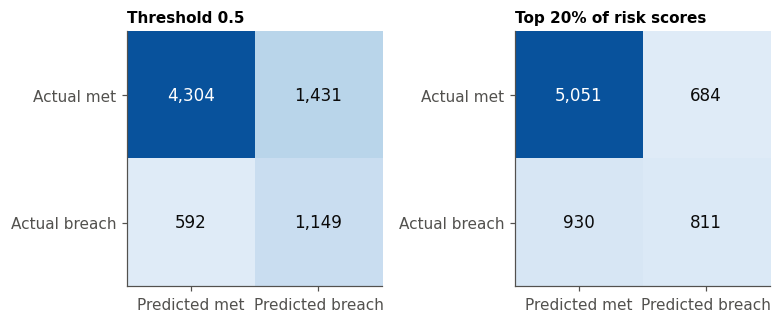

In [7]:
def at_top(y, s, k, seed=SEED):
    # flag the round(k*n) highest-risk tickets; ties (e.g. the four-level baseline) are broken at random
    n = int(round(k * len(s))); order = np.lexsort((np.random.default_rng(seed).random(len(s)), -s))
    yh = np.zeros(len(s), int); yh[order[:n]] = 1
    return {'k': k, 'flagged': int(yh.sum()), 'precision': round(precision_score(y, yh), 3), 'recall': round(recall_score(y, yh), 3),
            'lift': round(precision_score(y, yh) / y.mean(), 2)}
cap = {n: [at_top(y_te, s_te[n], k) for k in (0.10, 0.20, 0.30)] for n in ['Baseline: priority-only LR', 'Regularised LR', best, 'XGBoost']}
may = te[(te['opened_at'] >= '2016-05-02') & (te['opened_at'] < '2016-06-01')]
cap['test_days_may2016'] = {'incidents': len(may), 'days': int(may['opened_at'].dt.date.nunique()),
                            'mean_per_day': round(len(may) / may['opened_at'].dt.date.nunique(), 1)}
R['capacity'] = cap
o = np.argsort(-s_te[best]); yh20 = np.zeros(len(y_te), int); yh20[o[:int(round(0.2 * len(y_te)))]] = 1
R['confusion_top20'] = confusion_matrix(y_te, yh20).tolist(); R['confusion_05'] = confusion_matrix(y_te, (s_te[best] >= 0.5).astype(int)).tolist()
print(json.dumps(cap, indent=1)); print(R['confusion_top20'], R['confusion_05'])
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.3))
for ax, cm, ttl in [(axes[0], np.array(R['confusion_05']), 'Threshold 0.5'), (axes[1], np.array(R['confusion_top20']), 'Top 20% of risk scores')]:
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=cm.max() * 1.15); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', fontsize=11, color='white' if cm[i, j] > cm.max() * 0.6 else ps.INK)
    ax.set_xticks([0, 1], ['Predicted met', 'Predicted breach']); ax.set_yticks([0, 1], ['Actual met', 'Actual breach'])
    ax.set_title(ttl, fontsize=10)
fig.tight_layout(); fig.savefig(FIG / 'fig_confusion_rq4.png'); plt.show()

## 6. RQ2 robustness: banded reassignment with reassignment × priority interaction

In [8]:
cnt = inc['category'].fillna('Missing').value_counts()
inc['cat_grp'] = inc['category'].fillna('Missing').where(lambda s: s.map(cnt) >= 30, 'Other')
inc['band'] = pd.cut(inc['reassignment_count'], [-1, 0, 1, 2, 100], labels=['0', '1', '2', '3+']).astype(str)
# Critical and High (678 incidents) breach 98-99% of the time, so interaction terms there are not estimable (quasi-separation);
# the interaction is therefore tested within Moderate and Low priority (24,240 incidents, 97.3%).
ml = inc[inc['priority'].isin(['3 - Moderate', '4 - Low'])].copy()
m0 = smf.logit('sla_breach ~ C(band) + C(priority) + C(cat_grp)', data=ml).fit(disp=0, maxiter=300)
m1 = smf.logit('sla_breach ~ C(band) * C(priority) + C(cat_grp)', data=ml).fit(disp=0, maxiter=300)
lr = 2 * (m1.llf - m0.llf); dfd = int(m1.df_model - m0.df_model)
orp = {}
for p in ['3 - Moderate', '4 - Low']:
    orp[p] = {}
    for b in ['1', '2', '3+']:
        v = m1.params[f'C(band)[T.{b}]'] + m1.params.get(f'C(band)[T.{b}]:C(priority)[T.{p}]', 0.0)
        orp[p][b] = round(float(np.exp(v)), 2)
hl = inc[inc['priority'].isin(['1 - Critical', '2 - High'])]
R['rq2_interaction'] = {'n': len(ml), 'lr_chi2': round(lr, 1), 'df': dfd, 'p': float(chi2_dist.sf(lr, dfd)),
                        'or_band_main': {b: round(float(np.exp(m0.params[f'C(band)[T.{b}]'])), 2) for b in ['1', '2', '3+']},
                        'or_band_by_priority': orp,
                        'critical_high_breach_by_band': hl.groupby('band')['sla_breach'].agg(['mean', 'size']).round(3).to_dict('index')}
print(json.dumps(R['rq2_interaction'], indent=1))

{
 "n": 24240,
 "lr_chi2": 15.0,
 "df": 3,
 "p": 0.0018369420591205267,
 "or_band_main": {
  "1": 2.88,
  "2": 5.89,
  "3+": 12.78
 },
 "or_band_by_priority": {
  "3 - Moderate": {
   "1": 2.92,
   "2": 5.95,
   "3+": 13.17
  },
  "4 - Low": {
   "1": 1.51,
   "2": 3.26,
   "3+": 4.26
  }
 },
 "critical_high_breach_by_band": {
  "0": {
   "mean": 0.981,
   "size": 265
  },
  "1": {
   "mean": 0.99,
   "size": 201
  },
  "2": {
   "mean": 1.0,
   "size": 109
  },
  "3+": {
   "mean": 1.0,
   "size": 103
  }
 }
}


## 7. RQ3 robustness: knowledge-base effect before and after the March 2016 change

In [9]:
inc['knowledge'] = inc['knowledge'].astype(int); inc['period'] = np.where(inc['opened_at'] < '2016-03-21', 'pre', 'post')
out = {}
for per, g in inc.groupby('period'):
    mm = smf.logit('sla_breach ~ knowledge + C(priority) + C(cat_grp)', data=g).fit(disp=0, maxiter=300, method='bfgs')
    b, se = mm.params['knowledge'], mm.bse['knowledge']
    out[per] = {'n': len(g), 'knowledge_share': round(g['knowledge'].mean(), 3), 'breach_rate': round(g['sla_breach'].mean(), 3),
                'or_adj': round(float(np.exp(b)), 2), 'ci': [round(float(np.exp(b - 1.96 * se)), 2), round(float(np.exp(b + 1.96 * se)), 2)], 'p': float(mm.pvalues['knowledge'])}
strata = [pd.crosstab(g['knowledge'], g['sla_breach']).reindex(index=[1, 0], columns=[1, 0], fill_value=0).values for _, g in inc.groupby('period')]
st = StratifiedTable(strata)
out['mh_by_period'] = {'or': round(st.oddsratio_pooled, 2), 'ci': [round(x, 2) for x in st.oddsratio_pooled_confint()], 'mh_p': float(st.test_null_odds().pvalue), 'breslow_day_p': float(st.test_equal_odds().pvalue)}
R['rq3_by_period'] = out; print(json.dumps(out, indent=1))

{
 "post": {
  "n": 19012,
  "knowledge_share": 0.005,
  "breach_rate": 0.252,
  "or_adj": 1.17,
  "ci": [
   0.74,
   1.86
  ],
  "p": 0.5078860969515244
 },
 "pre": {
  "n": 5906,
  "knowledge_share": 0.586,
  "breach_rate": 0.731,
  "or_adj": 1.15,
  "ci": [
   1.01,
   1.31
  ],
  "p": 0.034593902598856995
 },
 "mh_by_period": {
  "or": 1.17,
  "ci": [
   1.05,
   1.31
  ],
  "mh_p": 0.005701110061222647,
  "breslow_day_p": 0.02632850642697071
 }
}


In [10]:
json.dump(R, open('../results/final_eval.json', 'w'), indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o)); print('saved')

saved
